In [ ]:
!pip install -q ucimlrepo scikit-learn pandas matplotlib seaborn


In [ ]:
import os
import random
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Seed:", SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [ ]:
!pip install -q ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# UCI Adult Income datasetini yuklash
adult = fetch_ucirepo(id=2)

# Features va target
X = adult.data.features.copy()
y = adult.data.targets.copy()

# Ustun nomlarini tozalash
X.columns = [
    str(col).strip().replace("-", "_")
    for col in X.columns
]

# Kategorik ustunlarni tozalash
for col in X.columns:
    if X[col].dtype == "object":
        X[col] = X[col].astype(str).str.strip()
        X[col] = X[col].replace("?", np.nan)

# Targetni tozalash
y = y.iloc[:, 0].astype(str).str.strip()

# 0 = daromad <=50K
# 1 = daromad >50K
y = (
    y.str.replace(".", "", regex=False) == ">50K"
).astype("int32")

# Natijalarni chiqarish
print("Dataset muvaffaqiyatli yuklandi!")
print("X o'lchami:", X.shape)
print("Y o'lchami:", y.shape)

print("\nBirinchi 5 ta qator:")
display(X.head())

print("\nTarget taqsimoti:")
print(y.value_counts())

print("\nUstunlar:")
print(X.columns.tolist())

Dataset muvaffaqiyatli yuklandi!
X o'lchami: (48842, 14)
Y o'lchami: (48842,)

Birinchi 5 ta qator:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba



Target taqsimoti:
income
0    37155
1    11687
Name: count, dtype: int64

Ustunlar:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']


Dataset o'lchami: (48842, 14)

Ma'lumot turlari:
age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
dtype: object

Yetishmayotgan qiymatlar:


,Missing Values,Percentage
age,0,0.00
workclass,1836,3.76
fnlwgt,0,0.00
education,0,0.00
education_num,0,0.00
marital_status,0,0.00
occupation,1843,3.77
relationship,0,0.00
race,0,0.00
sex,0,0.00


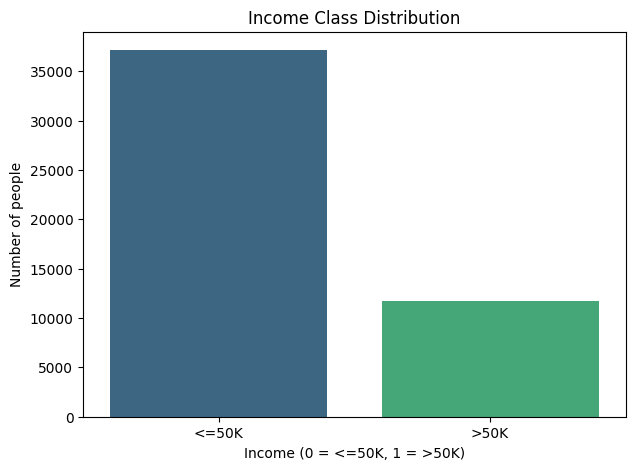

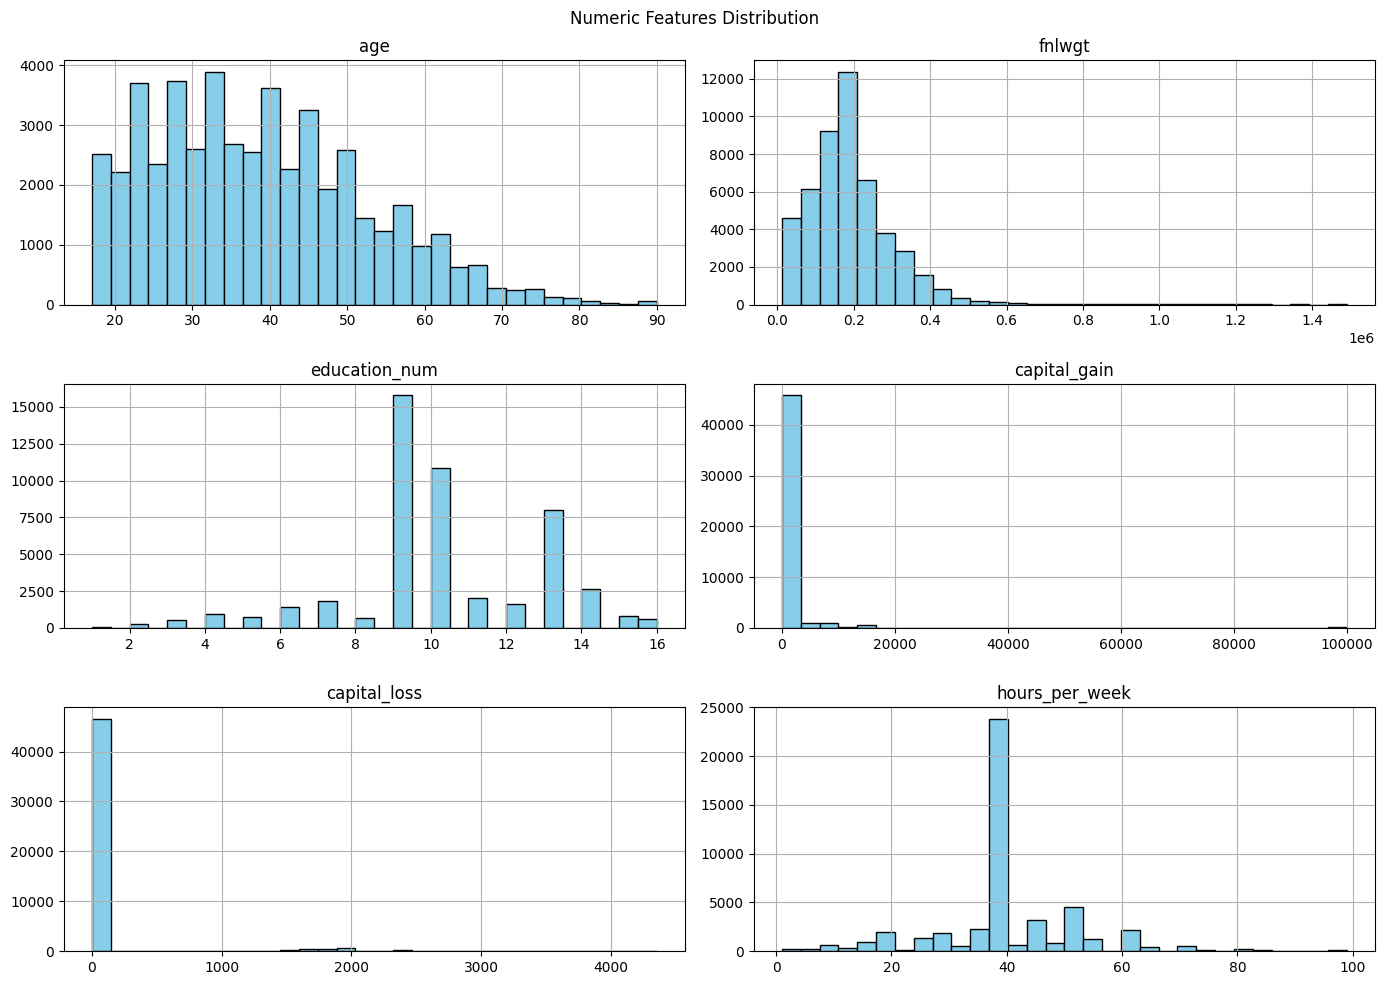

Numeric columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Numeric features: 6
Categorical features: 8


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Dataset haqida umumiy ma'lumot
print("Dataset o'lchami:", X.shape)

print("\nMa'lumot turlari:")
print(X.dtypes)

# Yetishmayotgan qiymatlarni tekshirish
print("\nYetishmayotgan qiymatlar:")
missing = X.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(X) * 100).round(2)
})

display(missing_table)

# Target taqsimoti
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="viridis",
    legend=False
)

plt.title("Income Class Distribution")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Number of people")
plt.xticks([0, 1], ["<=50K", ">50K"])
plt.show()

# Sonli xususiyatlar taqsimoti
numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

X[numeric_cols].hist(
    figsize=(14, 10),
    bins=30,
    color="skyblue",
    edgecolor="black"
)

plt.suptitle("Numeric Features Distribution")
plt.tight_layout()
plt.show()

# Kategorik va sonli ustunlar
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

print("\nNumeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

In [ ]:
from sklearn.model_selection import train_test_split

# Kategorik va sonli ustunlarni aniqlash
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

# Ma'lumotlarni tozalash
X_processed = X.copy()

# Kategorik qiymatlarni to'ldirish
for col in categorical_cols:
    X_processed[col] = X_processed[col].fillna("Unknown")

# Sonli qiymatlarni to'ldirish
for col in numeric_cols:
    X_processed[col] = pd.to_numeric(
        X_processed[col],
        errors="coerce"
    )

    X_processed[col] = X_processed[col].fillna(
        X_processed[col].median()
    )

# Train va vaqtinchalik qismlarga ajratish
X_train, X_temp, y_train, y_temp = train_test_split(
    X_processed,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Validation va test qismlariga ajratish
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nPreprocessing muvaffaqiyatli bajarildi!")

Train: (34189, 14)
Validation: (7326, 14)
Test: (7327, 14)

Preprocessing muvaffaqiyatli bajarildi!


In [ ]:
import tensorflow as tf
import numpy as np

# Kategorik ustunlar uchun Lookup
lookup_layers = {}

for col in categorical_cols:

    lookup = tf.keras.layers.StringLookup(
        output_mode="int",
        mask_token=None,
        num_oov_indices=1
    )

    lookup.adapt(
        X_train[col].astype(str).values
    )

    lookup_layers[col] = lookup


# Sonli ustunlar uchun Normalization
normalizer = tf.keras.layers.Normalization(
    axis=-1,
    name="numeric_normalization"
)

normalizer.adapt(
    X_train[numeric_cols].values.astype("float32")
)

print("StringLookup qatlamlari yaratildi!")
print("Normalization muvaffaqiyatli bajarildi!")

print("\nKategorik ustunlar:", len(categorical_cols))
print("Sonli ustunlar:", len(numeric_cols))

StringLookup qatlamlari yaratildi!
Normalization muvaffaqiyatli bajarildi!

Kategorik ustunlar: 8
Sonli ustunlar: 6


In [ ]:
def build_model():

    inputs = {}
    embedding_outputs = []

    # Kategorik tarmoq
    for col in categorical_cols:

        inp = tf.keras.Input(
            shape=(1,),
            dtype=tf.string,
            name=col
        )

        inputs[col] = inp

        encoded = lookup_layers[col](inp)

        vocab_size = lookup_layers[col].vocabulary_size()

        embedding_dim = min(
            16,
            max(4, int(np.ceil(np.sqrt(vocab_size))))
        )

        embedding = tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim
        )(encoded)

        embedding = tf.keras.layers.Flatten()(embedding)

        embedding_outputs.append(embedding)

    categorical_features = tf.keras.layers.Concatenate()(
        embedding_outputs
    )

    # Sonli tarmoq
    numeric_input = tf.keras.Input(
        shape=(len(numeric_cols),),
        dtype=tf.float32,
        name="numeric_features"
    )

    inputs["numeric_features"] = numeric_input

    numeric_features = normalizer(numeric_input)

    # Ikki tarmoqni birlashtirish
    combined = tf.keras.layers.Concatenate()([
        categorical_features,
        numeric_features
    ])

    x = tf.keras.layers.Dense(128, activation="relu")(combined)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.3)(x)

    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    output = tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return tf.keras.Model(inputs, output)


model = build_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ workclass           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ education           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ marital_status      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ occupation          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relationship        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ race (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sex (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ native_country      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup       │ (None, 1)         │          0 │ workclass[0][0]   │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_1     │ (None, 1)         │          0 │ education[0][0]   │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_2     │ (None, 1)         │          0 │ marital_status[0… │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_3     │ (None, 1)         │          0 │ occupation[0][0]  │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_4     │ (None, 1)         │          0 │ relationship[0][… │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_5     │ (None, 1)         │          0 │ race[0][0]        │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_6     │ (None, 1)         │          0 │ sex[0][0]         │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_7     │ (None, 1)         │          0 │ native_country[0… │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 4)      │         44 │ string_lookup[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 15,096 (58.97 KB)

 Trainable params: 14,827 (57.92 KB)

 Non-trainable params: 269 (1.05 KB)

In [ ]:
def dataframe_to_dict(df):

    result = {}

    for col in categorical_cols:
        result[col] = df[col].astype(str).values.reshape(-1, 1)

    result["numeric_features"] = df[
        numeric_cols
    ].values.astype("float32")

    return result


x_train = dataframe_to_dict(X_train)
x_val = dataframe_to_dict(X_val)
x_test = dataframe_to_dict(X_test)

y_train_np = y_train.values.astype("float32")
y_val_np = y_val.values.astype("float32")
y_test_np = y_test.values.astype("float32")

BATCH_SIZE = 256
EPOCHS = 20

def make_dataset(x, y, optimized=True, training=False):

    ds = tf.data.Dataset.from_tensor_slices((x, y))

    if optimized:
        ds = ds.cache()

    if training:
        ds = ds.shuffle(
            buffer_size=len(y),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)

    if optimized:
        ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = make_dataset(
    x_train, y_train_np,
    optimized=True,
    training=True
)

val_ds = make_dataset(
    x_val, y_val_np,
    optimized=True
)

test_ds = make_dataset(
    x_test, y_test_np,
    optimized=True
)

# 'age' o'rniga 'workclass' yoki 'numeric_features' ishlatamiz
print("Train dataset:", len(x_train["workclass"]))
print("Validation dataset:", len(x_val["workclass"]))
print("Test dataset:", len(x_test["workclass"]))

print("TensorFlow Dataset muvaffaqiyatli yaratildi!")

Train dataset: 34189
Validation dataset: 7326
Test dataset: 7327
TensorFlow Dataset muvaffaqiyatli yaratildi!


In [ ]:
# Model yaratish
model_fit = build_model()

# Modelni compile qilish
model_fit.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Boshlang'ich vaznlarni saqlash
initial_weights = model_fit.get_weights()

# Training vaqtini o'lchash
import time

start_time = time.perf_counter()

# Modelni o'qitish
history_fit = model_fit.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=1
)

fit_time = time.perf_counter() - start_time

print("\nModel o'qitish yakunlandi!")
print("Training time:", round(fit_time, 2), "seconds")


Epoch 1/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8137 - loss: 0.3949 - val_accuracy: 0.8452 - val_loss: 0.4027
Epoch 2/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8411 - loss: 0.3356 - val_accuracy: 0.8571 - val_loss: 0.3351
Epoch 3/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8481 - loss: 0.3270 - val_accuracy: 0.8590 - val_loss: 0.3134
Epoch 4/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8515 - loss: 0.3213 - val_accuracy: 0.8610 - val_loss: 0.3072
Epoch 5/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8513 - loss: 0.3190 - val_accuracy: 0.8609 - val_loss: 0.3054
Epoch 6/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8541 - loss: 0.3162 - val_accuracy: 0.8610 - val_loss: 0.3047
Epoch 7/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8535 - loss: 0.3144 - val_accuracy: 0.8624 - val_loss: 0.3047
Epoch 8/20
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8549 - loss: 0.3123 - val_accuracy: 

In [ ]:
# Ikkinchi modelni yaratamiz
model_tape = build_model()

# Birinchi modelning boshlang'ich vaznlarini beramiz
model_tape.set_weights(initial_weights)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

loss_function = tf.keras.losses.BinaryCrossentropy()

# Natijalarni saqlash
history_tape = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

train_loss_metric = tf.keras.metrics.Mean()
train_accuracy_metric = tf.keras.metrics.BinaryAccuracy()

val_loss_metric = tf.keras.metrics.Mean()
val_accuracy_metric = tf.keras.metrics.BinaryAccuracy()


@tf.function
def train_step(x_batch, y_batch):

    with tf.GradientTape() as tape:

        predictions = model_tape(
            x_batch,
            training=True
        )

        loss = loss_function(
            y_batch,
            predictions
        )

    gradients = tape.gradient(
        loss,
        model_tape.trainable_variables
    )

    optimizer.apply_gradients(
        zip(gradients, model_tape.trainable_variables)
    )

    train_loss_metric.update_state(loss)

    train_accuracy_metric.update_state(
        y_batch,
        predictions
    )


@tf.function
def validation_step(x_batch, y_batch):

    predictions = model_tape(
        x_batch,
        training=False
    )

    loss = loss_function(y_batch, predictions)

    val_loss_metric.update_state(loss)

    val_accuracy_metric.update_state(
        y_batch,
        predictions
    )


# O'qitish
start_time = time.perf_counter()

for epoch in range(20):

    train_loss_metric.reset_state()
    train_accuracy_metric.reset_state()

    val_loss_metric.reset_state()
    val_accuracy_metric.reset_state()

    for x_batch, y_batch in train_ds:
        train_step(x_batch, y_batch)

    for x_batch, y_batch in val_ds:
        validation_step(x_batch, y_batch)

    history_tape["loss"].append(
        float(train_loss_metric.result())
    )

    history_tape["accuracy"].append(
        float(train_accuracy_metric.result())
    )

    history_tape["val_loss"].append(
        float(val_loss_metric.result())
    )

    history_tape["val_accuracy"].append(
        float(val_accuracy_metric.result())
    )

    print(
        f"Epoch {epoch+1}/20 - "
        f"Loss: {history_tape['loss'][-1]:.4f} - "
        f"Accuracy: {history_tape['accuracy'][-1]:.4f} - "
        f"Val Accuracy: {history_tape['val_accuracy'][-1]:.4f}"
    )

tape_time = time.perf_counter() - start_time

print("\nGradientTape o'qitish tugadi!")
print("Training time:", round(tape_time, 2), "seconds")

Epoch 1/20 - Loss: 0.3967 - Accuracy: 0.8131 - Val Accuracy: 0.8505
Epoch 2/20 - Loss: 0.3336 - Accuracy: 0.8433 - Val Accuracy: 0.8571
Epoch 3/20 - Loss: 0.3250 - Accuracy: 0.8489 - Val Accuracy: 0.8598
Epoch 4/20 - Loss: 0.3211 - Accuracy: 0.8517 - Val Accuracy: 0.8606
Epoch 5/20 - Loss: 0.3174 - Accuracy: 0.8499 - Val Accuracy: 0.8598
Epoch 6/20 - Loss: 0.3156 - Accuracy: 0.8552 - Val Accuracy: 0.8627
Epoch 7/20 - Loss: 0.3129 - Accuracy: 0.8559 - Val Accuracy: 0.8612
Epoch 8/20 - Loss: 0.3126 - Accuracy: 0.8551 - Val Accuracy: 0.8605
Epoch 9/20 - Loss: 0.3100 - Accuracy: 0.8569 - Val Accuracy: 0.8624
Epoch 10/20 - Loss: 0.3077 - Accuracy: 0.8574 - Val Accuracy: 0.8630
Epoch 11/20 - Loss: 0.3083 - Accuracy: 0.8576 - Val Accuracy: 0.8625
Epoch 12/20 - Loss: 0.3072 - Accuracy: 0.8579 - Val Accuracy: 0.8635
Epoch 13/20 - Loss: 0.3050 - Accuracy: 0.8583 - Val Accuracy: 0.8608
Epoch 14/20 - Loss: 0.3076 - Accuracy: 0.8571 - Val Accuracy: 0.8627
Epoch 15/20 - Loss: 0.3036 - Accuracy: 0.85

In [ ]:
from sklearn.metrics import accuracy_score

# Test bashoratlari
pred_fit = model_fit.predict(test_ds, verbose=0).ravel()

pred_tape = model_tape.predict(test_ds, verbose=0).ravel()

# 0.5 threshold
pred_fit_labels = (pred_fit >= 0.5).astype(int)
pred_tape_labels = (pred_tape >= 0.5).astype(int)

# Accuracy
acc_fit = accuracy_score(y_test_np, pred_fit_labels)
acc_tape = accuracy_score(y_test_np, pred_tape_labels)

# Taqqoslash jadvali
comparison = pd.DataFrame({
    "Model": ["Keras model.fit()", "GradientTape"],
    "Test Accuracy": [acc_fit, acc_tape],
    "Training Time (sec)": [fit_time, tape_time]
})

display(comparison.round(4))

comparison.to_csv("training_comparison.csv", index=False)

print("Test natijalari muvaffaqiyatli hisoblandi!")

,Model,Test Accuracy,Training Time (sec)
0,Keras model.fit(),0.8594,37.1728
1,GradientTape,0.8615,27.4019


Test natijalari muvaffaqiyatli hisoblandi!


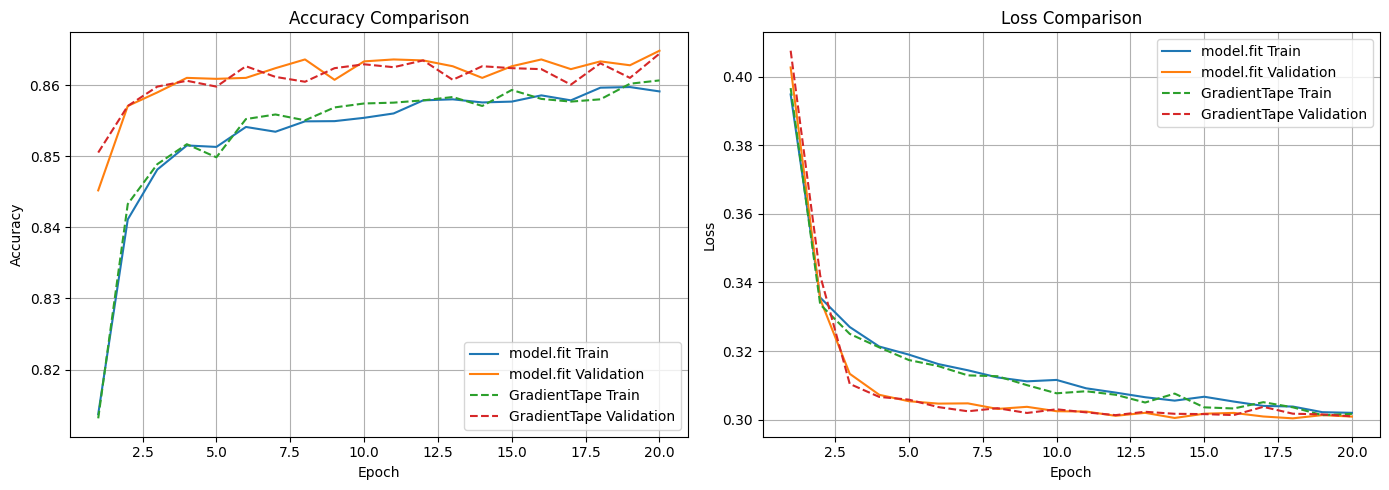

In [ ]:
epochs_range = range(1, 21)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(epochs_range,
         history_fit.history["accuracy"],
         label="model.fit Train")

plt.plot(epochs_range,
         history_fit.history["val_accuracy"],
         label="model.fit Validation")

plt.plot(epochs_range,
         history_tape["accuracy"],
         "--",
         label="GradientTape Train")

plt.plot(epochs_range,
         history_tape["val_accuracy"],
         "--",
         label="GradientTape Validation")

plt.title("Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(epochs_range,
         history_fit.history["loss"],
         label="model.fit Train")

plt.plot(epochs_range,
         history_fit.history["val_loss"],
         label="model.fit Validation")

plt.plot(epochs_range,
         history_tape["loss"],
         "--",
         label="GradientTape Train")

plt.plot(epochs_range,
         history_tape["val_loss"],
         "--",
         label="GradientTape Validation")

plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

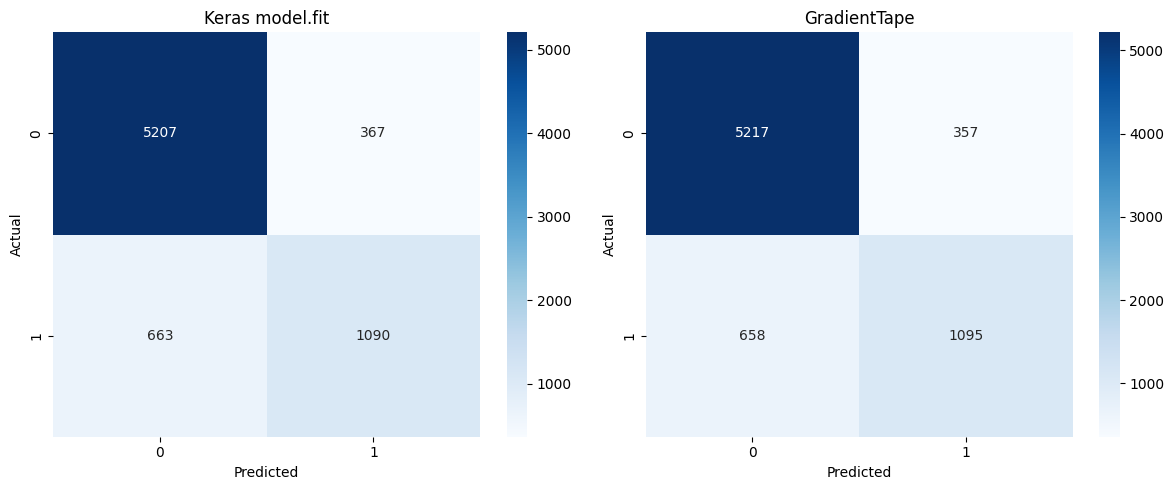

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in [
    (axes[0], pred_fit_labels, "Keras model.fit"),
    (axes[1], pred_tape_labels, "GradientTape")
]:

    cm = confusion_matrix(y_test_np, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
def benchmark_pipeline(optimized, repeats=3):

    ds = make_dataset(
        x_train,
        y_train_np,
        optimized=optimized,
        training=True
    )

    times = []

    for epoch in range(repeats):

        start = time.perf_counter()

        for batch_x, batch_y in ds:
            pass

        times.append(time.perf_counter() - start)

    return times


normal_times = benchmark_pipeline(False)
optimized_times = benchmark_pipeline(True)

pipeline_results = pd.DataFrame({
    "Epoch": [1, 2, 3],
    "Without Cache/Prefetch": normal_times,
    "With Cache/Prefetch": optimized_times
})

display(pipeline_results.round(4))

pipeline_results.to_csv(
    "pipeline_benchmark.csv",
    index=False
)

,Epoch,Without Cache/Prefetch,With Cache/Prefetch
0,1,0.6345,0.3377
1,2,0.5214,0.2369
2,3,0.4455,0.2325


In [ ]:
model_fit.save("adult_income_model.keras")
model_tape.save("adult_income_gradient_tape.keras")

print("Ikkala model ham saqlandi!")

Ikkala model ham saqlandi!


In [ ]:
from sklearn.metrics import accuracy_score

pred_fit = model_fit.predict(test_ds, verbose=0).ravel()
pred_tape = model_tape.predict(test_ds, verbose=0).ravel()

pred_fit_labels = (pred_fit >= 0.5).astype(int)
pred_tape_labels = (pred_tape >= 0.5).astype(int)

acc_fit = accuracy_score(y_test_np, pred_fit_labels)
acc_tape = accuracy_score(y_test_np, pred_tape_labels)

comparison = pd.DataFrame({
    "Model": ["model.fit()", "GradientTape"],
    "Test Accuracy": [acc_fit, acc_tape],
    "Training Time": [fit_time, tape_time]
})

display(comparison.round(4))

,Model,Test Accuracy,Training Time
0,model.fit(),0.8594,37.1728
1,GradientTape,0.8615,27.4019


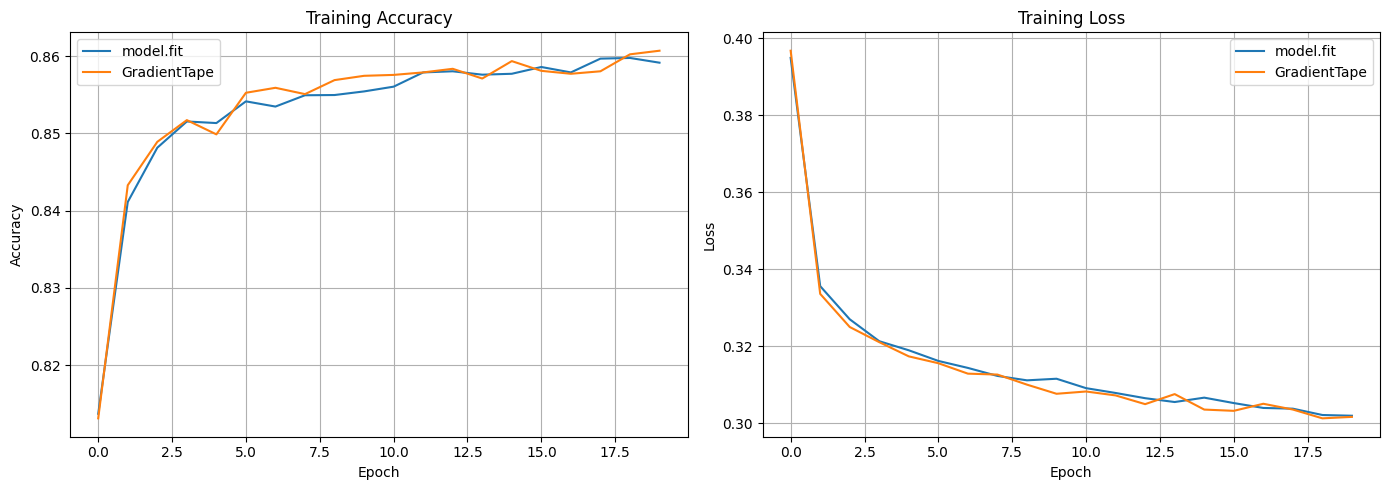

In [ ]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history_fit.history["accuracy"], label="model.fit")
plt.plot(history_tape["accuracy"], label="GradientTape")

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history_fit.history["loss"], label="model.fit")
plt.plot(history_tape["loss"], label="GradientTape")

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

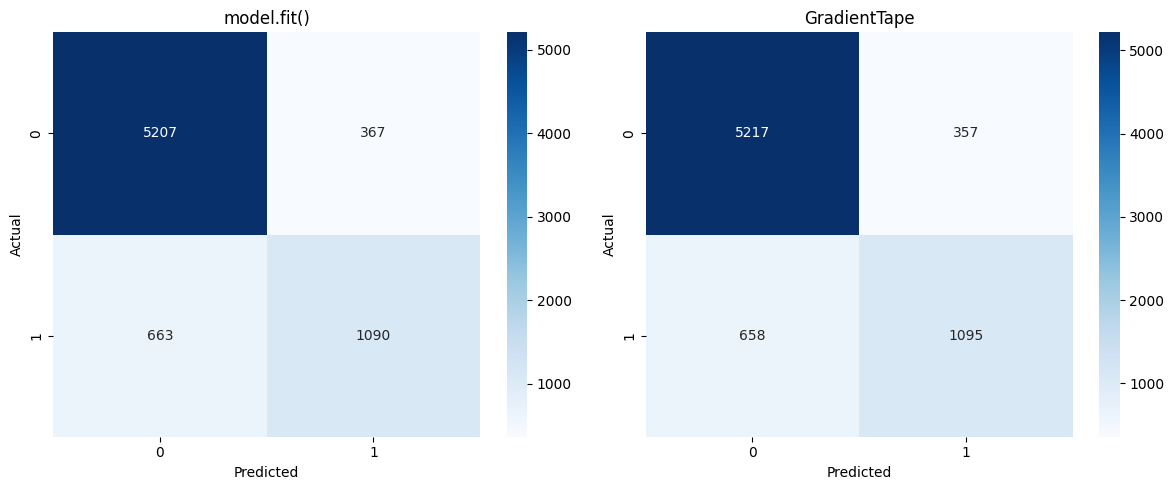

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in [
    (axes[0], pred_fit_labels, "model.fit()"),
    (axes[1], pred_tape_labels, "GradientTape")
]:

    cm = confusion_matrix(y_test_np, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

,Epoch,Without optimization,Cache + Prefetch
0,1,0.6329,0.6367
1,2,0.7476,0.4607
2,3,0.6292,0.2605


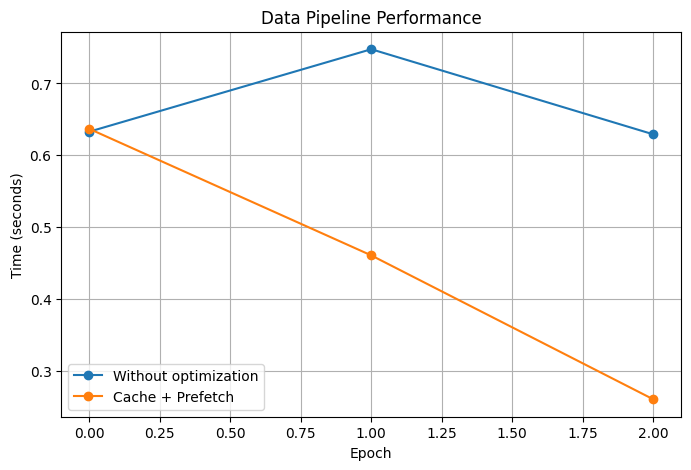

In [ ]:
normal_times = benchmark_pipeline(False)
optimized_times = benchmark_pipeline(True)

pipeline_results = pd.DataFrame({
    "Epoch": [1, 2, 3],
    "Without optimization": normal_times,
    "Cache + Prefetch": optimized_times
})

display(pipeline_results.round(4))

pipeline_results.to_csv(
    "pipeline_benchmark.csv",
    index=False
)

plt.figure(figsize=(8, 5))

plt.plot(normal_times, marker="o", label="Without optimization")
plt.plot(optimized_times, marker="o", label="Cache + Prefetch")

plt.title("Data Pipeline Performance")
plt.xlabel("Epoch")
plt.ylabel("Time (seconds)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
comparison.to_csv("training_comparison.csv", index=False)

print("Barcha natijalar saqlandi!")

Barcha natijalar saqlandi!
